# Warby Parker Customer Conversion Funnel Analysis

Python analysis (pandas, numpy, matplotlib, seaborn).

## Data Inspection

**Business question:** Before analysing the customer journey, what data do we have and what does each table contain?

**Method:** Load the four CSV files, look at the first rows, check the size and data types, and work out what each column means.

**Note:** The CSV files have no header row, so we load them with `header=None` and name the columns ourselves after looking at the values.

### Step 1: Import Pandas

Pandas is the library we use to load and work with tables of data.

In [1]:
# Import pandas with the usual short name
import pandas as pd

### Step 2: Load the four CSV files

`header=None` tells pandas the first line is real data, not column names. Without it, pandas would treat the first customer in each file as a header and we would lose that row.

In [2]:
# Load each CSV file from the data folder (the original files are only read, never changed)
survey = pd.read_csv("data/survey.csv", header=None)
quiz = pd.read_csv("data/quiz.csv", header=None)
home_try_on = pd.read_csv("data/home_try_on.csv", header=None)
purchase = pd.read_csv("data/purchase.csv", header=None)

### Step 3: First five rows of each dataset

Looking at a few rows is the quickest way to see what each table holds. The columns are numbered 0, 1, 2... for now because we have not named them yet.

In [3]:
# Show the first five rows of each dataset
print("SURVEY")
print(survey.head())
print()
print("QUIZ")
print(quiz.head())
print()
print("HOME TRY-ON")
print(home_try_on.head())
print()
print("PURCHASE")
print(purchase.head())

SURVEY
                              0                                     1  \
0  1. What are you looking for?  005e7f99-d48c-4fce-b605-10506c85aaf7   
1           2. What's your fit?  005e7f99-d48c-4fce-b605-10506c85aaf7   
2           3. How old are you?  00a556ed-f13e-4c67-8704-27e3573684cd   
3  4. Which colors do you like?  00a556ed-f13e-4c67-8704-27e3573684cd   
4  1. What are you looking for?  00a556ed-f13e-4c67-8704-27e3573684cd   

                              2  
0                Women's Styles  
1                        Medium  
2                         Round  
3                      Two-Tone  
4  I'm not sure. Let's skip it.  

QUIZ
                                      0               1       2            3  \
0  4e8118dc-bb3d-49bf-85fc-cca8d83232ac  Women's Styles  Medium  Rectangular   
1  291f1cca-e507-48be-b063-002b14906468  Women's Styles  Narrow        Round   
2  75122300-0736-4087-b6d8-c0c5373a1a04  Women's Styles    Wide  Rectangular   
3  75bc6ebd-40cd-4e1d-a3

### Step 4: Number of rows and columns

`.shape` returns (rows, columns). Because we used `header=None`, every row is a real record.

In [4]:
# Check the size of each dataset: (rows, columns)
print("survey:", survey.shape)
print("quiz:", quiz.shape)
print("home_try_on:", home_try_on.shape)
print("purchase:", purchase.shape)

survey: (1986, 3)
quiz: (1000, 5)
home_try_on: (750, 3)
purchase: (495, 6)


### Step 5: Data types and non-null counts

`.info()` shows each column's data type and how many values are not missing. If the non-null count equals the number of rows, the column has no missing values. Text columns appear as `str` in this version of pandas (older versions show `object`).

In [5]:
# Data types and non-null counts for each dataset
print("SURVEY")
survey.info()
print()
print("QUIZ")
quiz.info()
print()
print("HOME TRY-ON")
home_try_on.info()
print()
print("PURCHASE")
purchase.info()

SURVEY
<class 'pandas.DataFrame'>
RangeIndex: 1986 entries, 0 to 1985
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       1986 non-null   str  
 1   1       1986 non-null   str  
 2   2       1986 non-null   str  
dtypes: str(3)
memory usage: 182.7 KB

QUIZ
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       1000 non-null   str  
 1   1       1000 non-null   str  
 2   2       1000 non-null   str  
 3   3       1000 non-null   str  
 4   4       1000 non-null   str  
dtypes: str(5)
memory usage: 110.9 KB

HOME TRY-ON
<class 'pandas.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       750 non-null    str  
 1   1       750 non-null    str  
 2   2       750 non-null    str  
dtypes: str(3)
memory

### Step 6: Examine the values to name the columns

We cannot guess column names, so we start by counting how many different values each column has. A column with a different value in every row is probably an ID, and a column with only a few different values is probably a category.

In [6]:
# Number of different values in each column
print("survey")
print(survey.nunique())
print()
print("quiz")
print(quiz.nunique())
print()
print("home_try_on")
print(home_try_on.nunique())
print()
print("purchase")
print(purchase.nunique())

survey
0      5
1    500
2     19
dtype: int64

quiz
0    1000
1       3
2       4
3       4
4       5
dtype: int64

home_try_on
0    750
1      2
2    749
dtype: int64

purchase
0    495
1     10
2      2
3      6
4      9
5      3
dtype: int64


Next we look at the actual values in the columns that have only a few different values. `.value_counts()` lists each value and how many times it appears.

In [7]:
# Survey: which questions are asked?
print(survey[0].value_counts())
print()

# Quiz: the four answer columns
print(quiz[1].value_counts())
print()
print(quiz[2].value_counts())
print()
print(quiz[3].value_counts())
print()
print(quiz[4].value_counts())

0
1. What are you looking for?       500
2. What's your fit?                475
3. How old are you?                380
4. Which colors do you like?       361
5. When was your last eye exam?    270
Name: count, dtype: int64

1
Women's Styles                  469
Men's Styles                    432
I'm not sure. Let's skip it.     99
Name: count, dtype: int64

2
Narrow                          408
Medium                          305
Wide                            198
I'm not sure. Let's skip it.     89
Name: count, dtype: int64

3
Rectangular      397
Square           326
Round            180
No Preference     97
Name: count, dtype: int64

4
Tortoise    292
Black       280
Crystal     210
Neutral     114
Two-Tone    104
Name: count, dtype: int64


In [8]:
# Home try-on: how many pairs were sent?
print(home_try_on[1].value_counts())
print()

# Purchase: the category columns and the price
print(purchase[1].value_counts().sort_index())
print()
print(purchase[2].value_counts())
print()
print(purchase[3].value_counts())
print()
print(purchase[4].value_counts())
print()
print(purchase[5].value_counts())

1
3 pairs    379
5 pairs    371
Name: count, dtype: int64

1
1     52
2     43
3     63
4     44
5     41
6     50
7     44
8     42
9     54
10    62
Name: count, dtype: int64

2
Women's Styles    252
Men's Styles      243
Name: count, dtype: int64

3
Eugene Narrow    116
Dawes            107
Brady             95
Lucy              86
Olive             50
Monocle           41
Name: count, dtype: int64

4
Jet Black                 86
Driftwood Fade            63
Rosewood Tortoise         62
Rose Crystal              54
Layered Tortoise Matte    52
Pearled Tortoise          50
Elderflower Crystal       44
Sea Glass Gray            43
Endangered Tortoise       41
Name: count, dtype: int64

5
95     261
150    193
50      41
Name: count, dtype: int64


The survey answers (column 2) belong to different questions, so we list the different answers separately for each question. We also look at a few values from the columns with too many different values to count, which are the ID columns and the home try-on column 2.

In [9]:
# Survey: the different answers given to each question
for question in sorted(survey[0].unique()):
    print(question)
    print(sorted(survey[survey[0] == question][2].unique()))
    print()

1. What are you looking for?
["I'm not sure. Let's skip it.", "Men's Styles", "Women's Styles"]

2. What's your fit?
["I'm not sure. Let's skip it.", 'Medium', 'Narrow', 'Wide']

3. How old are you?
['No Preference', 'Rectangular', 'Round', 'Square']

4. Which colors do you like?
['Black', 'Crystal', 'Neutral', 'Tortoise', 'Two-Tone']

5. When was your last eye exam?
['1-3 Years', '3+ Years', '<1 Year', "Not Sure. Let's Skip It"]



In [10]:
# A few values from the ID columns and the home try-on column 2
print(survey[1].head(3))
print()
print(quiz[0].head(3))
print()
print(home_try_on[2].head(5))

0    005e7f99-d48c-4fce-b605-10506c85aaf7
1    005e7f99-d48c-4fce-b605-10506c85aaf7
2    00a556ed-f13e-4c67-8704-27e3573684cd
Name: 1, dtype: str

0    4e8118dc-bb3d-49bf-85fc-cca8d83232ac
1    291f1cca-e507-48be-b063-002b14906468
2    75122300-0736-4087-b6d8-c0c5373a1a04
Name: 0, dtype: str

0         145 New York 9a
1         383 Madison Ave
2             287 Pell St
3    347 Madison Square N
4         182 Cornelia St
Name: 2, dtype: str


### Step 7: Assign column names

Now that we know what each column holds, we give the columns meaningful names. We print the first rows afterwards to check that the names match the values.

In [11]:
# Give each dataset meaningful column names
survey.columns = ["question", "user_id", "response"]
quiz.columns = ["user_id", "style", "fit", "shape", "color"]
home_try_on.columns = ["user_id", "number_of_pairs", "address"]
purchase.columns = ["user_id", "product_id", "style", "model_name", "color", "price"]

# Check that the new names match the values
print(survey.head(3))
print()
print(quiz.head(3))
print()
print(home_try_on.head(3))
print()
print(purchase.head(3))

                       question                               user_id  \
0  1. What are you looking for?  005e7f99-d48c-4fce-b605-10506c85aaf7   
1           2. What's your fit?  005e7f99-d48c-4fce-b605-10506c85aaf7   
2           3. How old are you?  00a556ed-f13e-4c67-8704-27e3573684cd   

         response  
0  Women's Styles  
1          Medium  
2           Round  

                                user_id           style     fit        shape  \
0  4e8118dc-bb3d-49bf-85fc-cca8d83232ac  Women's Styles  Medium  Rectangular   
1  291f1cca-e507-48be-b063-002b14906468  Women's Styles  Narrow        Round   
2  75122300-0736-4087-b6d8-c0c5373a1a04  Women's Styles    Wide  Rectangular   

      color  
0  Tortoise  
1     Black  
2  Two-Tone  

                                user_id number_of_pairs          address
0  d8addd87-3217-4429-9a01-d56d68111da7         5 pairs  145 New York 9a
1  f52b07c8-abe4-4f4a-9d39-ba9fc9a184cc         5 pairs  383 Madison Ave
2  8ba0d2d5-1a31-403e-9fa5-79

### Step 8: Summary of the data inspection

| Dataset | Rows | Columns | Column names | What one row means |
|---|---|---|---|---|
| `survey` | 1,986 | 3 | question, user_id, response | One answer to one survey question |
| `quiz` | 1,000 | 5 | user_id, style, fit, shape, color | One customer's Style Quiz answers |
| `home_try_on` | 750 | 3 | user_id, number_of_pairs, address | One customer who received a home try-on box |
| `purchase` | 495 | 6 | user_id, product_id, style, model_name, color, price | One customer's purchase |

**Findings**

1. **No header row.** None of the four files has column names, so we loaded them with `header=None` and named the columns from the values.
2. **No missing values.** In every table, each column's non-null count equals the number of rows.
3. **Data types.** All columns are text (`str`) except `product_id` and `price` in `purchase`, which are whole numbers (`int64`).
4. **One row per customer in three tables.** In `quiz`, `home_try_on` and `purchase`, the number of different IDs equals the number of rows (1,000, 750 and 495). The `survey` has 500 different IDs in 1,986 rows because each customer answers several questions.
5. **Funnel sizes.** There are 1,000 rows in the quiz, 750 in home try-on and 495 in purchase. These are only row counts, and we have not yet checked that the same customers appear in each table.
6. **A/B test groups.** `number_of_pairs` has two groups: 3 pairs (379 rows) and 5 pairs (371 rows).

**Points to check in the next step (cleaning and validation)**

- **Survey question 3.** The question says "How old are you?" but its answers are frame shapes (Rectangular, Square, Round, No Preference).
- **Placeholder answers.** "I'm not sure. Let's skip it." and "No Preference" appear as answers. They are real answers, not missing values, but need careful handling.
- **Address.** `home_try_on` has 749 different addresses in 750 rows, so one address appears twice.
- **Matching IDs.** We have not checked whether the IDs match across the tables.
- **Duplicates.** We have not yet checked for duplicate rows.

---
## Data Cleaning and Validation

**Business question:** Can we trust these four tables enough to build the conversion funnel and the A/B test on them?

**Method:** Check for duplicates, missing values, formatting problems, matching customer IDs and sensible values. We only change the data if a check shows a real problem. Every decision is written down at the end.

In [12]:
# Put the four tables in one dictionary so we can run the same check on each of them
tables = {"survey": survey, "quiz": quiz, "home_try_on": home_try_on, "purchase": purchase}

### Step 1: Duplicates

A customer should appear only once in `quiz`, `home_try_on` and `purchase`. In `survey` a customer appears once per question, so we check that nobody answered the same question twice.

In [13]:
# Fully duplicated rows in each table
for name, table in tables.items():
    print(name, "- duplicate rows:", table.duplicated().sum())

print()

# Repeated customer IDs (should be 0 in these three tables)
print("quiz - repeated user_id:", quiz["user_id"].duplicated().sum())
print("home_try_on - repeated user_id:", home_try_on["user_id"].duplicated().sum())
print("purchase - repeated user_id:", purchase["user_id"].duplicated().sum())

# Survey: the same customer answering the same question twice (should be 0)
print("survey - repeated user_id + question:", survey.duplicated(["user_id", "question"]).sum())

print()

# The address that appears twice in home_try_on (found during the inspection)
print(home_try_on[home_try_on["address"].duplicated(keep=False)])

survey - duplicate rows: 0
quiz - duplicate rows: 0
home_try_on - duplicate rows: 0
purchase - duplicate rows: 0

quiz - repeated user_id: 0
home_try_on - repeated user_id: 0
purchase - repeated user_id: 0
survey - repeated user_id + question: 0

                                  user_id number_of_pairs         address
623  480e65fe-c8a0-4b3a-bfb4-7ce31be93d52         5 pairs  369 Craig Rd S
675  76bbf5e1-5eb3-468c-accc-7eb492d47b28         5 pairs  369 Craig Rd S


**Result:** There are no duplicate rows and no repeated customer IDs. The repeated address belongs to two different customers who both received 5 pairs. This is plausible (for example, people living in the same building), so we keep both rows.

### Step 2: Missing values and extra spaces

The data inspection showed no missing values. Here we confirm that, and also check for hidden spaces at the start or end of text, which would make identical answers look different.

In [14]:
# Missing values in each table
for name, table in tables.items():
    print(name, "- missing values:", table.isna().sum().sum())

print()

# Text values with extra spaces at the start or end
for name, table in tables.items():
    for column in table.columns:
        text = table[column].astype(str)
        extra_spaces = (text != text.str.strip()).sum()
        if extra_spaces > 0:
            print(name, column, "- values with extra spaces:", extra_spaces)

print("Extra-space check finished")

survey - missing values: 0
quiz - missing values: 0
home_try_on - missing values: 0
purchase - missing values: 0

Extra-space check finished


**Result:** There are no missing values and no values with extra spaces. Answers such as "I'm not sure. Let's skip it." and "No Preference" are genuine customer answers, not missing data, so we keep them.

### Step 3: Do the customer IDs match across tables?

The funnel only works if the tables follow the same customers: everyone in `home_try_on` should be in `quiz`, and everyone in `purchase` should be in `home_try_on`. We also test that joining the tables does not create extra rows.

In [15]:
# How many customers in each later stage also exist in the earlier stage?
home_try_on_in_quiz = home_try_on["user_id"].isin(quiz["user_id"]).sum()
purchase_in_home_try_on = purchase["user_id"].isin(home_try_on["user_id"]).sum()
survey_in_quiz = survey["user_id"].isin(quiz["user_id"]).sum()

print("home_try_on customers found in quiz:", home_try_on_in_quiz, "of", len(home_try_on))
print("purchase customers found in home_try_on:", purchase_in_home_try_on, "of", len(purchase))
print("survey rows with a customer found in quiz:", survey_in_quiz, "of", len(survey))

print()

# Join test: starting from quiz, LEFT JOIN the other two tables. The row count must stay at 1000.
funnel = quiz.merge(home_try_on, on="user_id", how="left").merge(purchase, on="user_id", how="left")
print("quiz rows:", len(quiz))
print("rows after joining home_try_on and purchase:", len(funnel))

home_try_on customers found in quiz: 750 of 750
purchase customers found in home_try_on: 495 of 495
survey rows with a customer found in quiz: 0 of 1986

quiz rows: 1000
rows after joining home_try_on and purchase: 1000


**Result:**

- Every `home_try_on` customer is in `quiz`, and every `purchase` customer is in `home_try_on`. The funnel is therefore strictly step by step: Quiz (1,000) → Home Try-On (750) → Purchase (495).
- Joining the tables keeps 1,000 rows, so the joins do not duplicate customers.
- **Important limitation:** none of the survey customer IDs appear in `quiz`. The `survey` table is a separate group of 500 customers, so it cannot be joined to the funnel. We can still use it on its own to see where people leave the quiz questions.

### Step 4: Are the values sensible?

We check that prices, product IDs and pair counts take only the expected values, and that they are consistent with each other.

In [16]:
# Values that should come from a small fixed list
print("Prices:", purchase["price"].sort_values().unique().tolist())
print("Product IDs:", purchase["product_id"].sort_values().unique().tolist())
print("Number of pairs:", sorted(home_try_on["number_of_pairs"].unique()))

print()

# Each model should have one price (1 means consistent)
print("Different prices per model:")
print(purchase.groupby("model_name")["price"].nunique())

print()

# Each product ID should be one model in one colour (1 means consistent)
print("Different models and colours per product ID:")
print(purchase.groupby("product_id")[["model_name", "color"]].nunique())

Prices: [50, 95, 150]
Product IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Number of pairs: ['3 pairs', '5 pairs']

Different prices per model:
model_name
Brady            1
Dawes            1
Eugene Narrow    1
Lucy             1
Monocle          1
Olive            1
Name: price, dtype: int64

Different models and colours per product ID:
            model_name  color
product_id                   
1                    1      1
2                    1      1
3                    1      1
4                    1      1
5                    1      1
6                    1      1
7                    1      1
8                    1      1
9                    1      1
10                   1      1


**Result:** Prices are 50, 95 or 150, product IDs run from 1 to 10 and `number_of_pairs` is only 3 or 5. Each model has exactly one price and each product ID is exactly one model and colour, so the purchase data is consistent.

### Step 5: The survey table

In the data inspection we saw that question 3 is "How old are you?" but its answers look like frame shapes. We compare those answers with the `shape` column in `quiz`, and check how many questions each customer answered, because this will show where customers leave the quiz.

In [17]:
# Are the answers to question 3 the same as the shape options in the quiz?
question_3_answers = survey[survey["question"] == "3. How old are you?"]["response"]
print("Question 3 answers:", sorted(question_3_answers.unique()))
print("Quiz shape values:", sorted(quiz["shape"].unique()))

print()

# How many customers answered each question?
print(survey["question"].value_counts().sort_index())

print()

# How many questions did each customer answer?
questions_per_customer = survey.groupby("user_id").size()
print(questions_per_customer.value_counts().sort_index())

Question 3 answers: ['No Preference', 'Rectangular', 'Round', 'Square']
Quiz shape values: ['No Preference', 'Rectangular', 'Round', 'Square']

question
1. What are you looking for?       500
2. What's your fit?                475
3. How old are you?                380
4. Which colors do you like?       361
5. When was your last eye exam?    270
Name: count, dtype: int64

1     25
2     95
3     19
4     91
5    270
Name: count, dtype: int64


**Result:**

- The answers to question 3 are exactly the shape options in `quiz` (Rectangular, Square, Round, No Preference). The question text "How old are you?" therefore looks like a labelling error, and the question is really about frame shape. We cannot confirm this from the data alone, so we will treat the answers as shape and not use them as age.
- Fewer customers answer each later question: 500, 475, 380, 361 and 270. This is the quiz drop-off we will measure next.
- The counts per customer fit this pattern: 25 customers stopped after question 1, 95 after question 2, 19 after question 3, 91 after question 4, and 270 answered all five.

### Step 6: Summary of the cleaning and validation

| Check | Result | Decision |
|---|---|---|
| Duplicate rows | None | Nothing to remove |
| Repeated customer IDs | None in `quiz`, `home_try_on`, `purchase` | Each row is one customer |
| Missing values | None | Nothing to fill |
| Extra spaces in text | None | No text cleaning needed |
| Repeated address | 2 different customers, both 5 pairs | Keep both |
| "I'm not sure" and "No Preference" answers | Real answers | Keep as categories |
| Funnel IDs match | 750 of 750 and 495 of 495 | Funnel is strictly step by step |
| Joins | 1,000 rows before and after | Safe to join from `quiz` |
| Prices and product IDs | Valid and consistent | No changes |
| Survey customer IDs in `quiz` | 0 of 500 match | Use `survey` on its own, not joined |
| Survey question 3 | Answers are frame shapes, not ages | Treat as shape, flag in the write-up |

**Conclusion:** The data is clean. No rows or values were changed, so the tables from the inspection can be used as they are.

**Limitations to remember**

- The survey cannot be linked to the funnel because the customer IDs do not match, so we cannot say which survey customers later bought glasses.
- The label of survey question 3 appears to be wrong.
- The data is fictional, and the files do not tell us how customers were assigned to 3 or 5 pairs. We cannot assume the groups were randomly assigned, and this affects how we interpret the A/B test later.

**Next:** the SQL funnel analysis.

---
## Create the SQLite Database

**Business question:** How do customers move through the funnel from the Style Quiz to Home Try-On to Purchase?

**Method:** The funnel is calculated with SQL queries (saved in `analysis.sql`). SQL needs a database, so we save the four named tables into a small SQLite file called `warby_parker.db`. The CSV files are only read, never changed.

In [18]:
# Import the sqlite3 library that comes with Python
import sqlite3

# Create (or open) the database file
connection = sqlite3.connect("warby_parker.db")

# Save each table into the database. index=False stops pandas from adding an extra index column
survey.to_sql("survey", connection, if_exists="replace", index=False)
quiz.to_sql("quiz", connection, if_exists="replace", index=False)
home_try_on.to_sql("home_try_on", connection, if_exists="replace", index=False)
purchase.to_sql("purchase", connection, if_exists="replace", index=False)

# Check that every table was saved with the right number of rows
for table_name in ["survey", "quiz", "home_try_on", "purchase"]:
    row_count = pd.read_sql(f"SELECT COUNT(*) AS rows_saved FROM {table_name}", connection)
    print(table_name, "-", row_count["rows_saved"][0], "rows")

connection.close()

survey - 1986 rows
quiz - 1000 rows
home_try_on - 750 rows
purchase - 495 rows


---
## Exploratory Data Analysis

**Business question:** Where do customers drop out of the journey, and what do the quiz answers, the number of pairs and the products look like?

**Method:** Build one table with one row per quiz customer, then use charts and simple summary tables. This section only describes the data. Statistical testing comes later.

### Step 1: Set up the charts and build the funnel table

The funnel table starts from every quiz customer. Two True/False columns record whether each customer received a home try-on box and whether they purchased. We use a LEFT JOIN style merge, so customers who stop early are still included.

In [19]:
# Import the plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Chart settings: a clean look and two colours used throughout
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
blue = "#2a78d6"
orange = "#eb6834"

In [20]:
# One row per quiz customer, with the number of pairs they were sent (empty if no home try-on)
funnel = quiz.merge(home_try_on[["user_id", "number_of_pairs"]], on="user_id", how="left")

# True/False columns for the two later stages
funnel["got_home_try_on"] = funnel["number_of_pairs"].notna()
funnel["purchased"] = funnel["user_id"].isin(purchase["user_id"])

# The merge must not add or remove customers
print("Quiz customers:", len(quiz))
print("Rows in funnel table:", len(funnel))
print()
print(funnel.head())

Quiz customers: 1000
Rows in funnel table: 1000

                                user_id           style     fit        shape  \
0  4e8118dc-bb3d-49bf-85fc-cca8d83232ac  Women's Styles  Medium  Rectangular   
1  291f1cca-e507-48be-b063-002b14906468  Women's Styles  Narrow        Round   
2  75122300-0736-4087-b6d8-c0c5373a1a04  Women's Styles    Wide  Rectangular   
3  75bc6ebd-40cd-4e1d-a301-27ddd93b12e2  Women's Styles  Narrow       Square   
4  ce965c4d-7a2b-4db6-9847-601747fa7812  Women's Styles    Wide  Rectangular   

      color number_of_pairs  got_home_try_on  purchased  
0  Tortoise         3 pairs             True      False  
1     Black         3 pairs             True       True  
2  Two-Tone             NaN            False      False  
3  Two-Tone         5 pairs             True      False  
4     Black         3 pairs             True       True  


### Step 2: Where do customers leave the quiz?

The survey shows how many customers answered each question. These are the survey customers, a separate group from the funnel table.

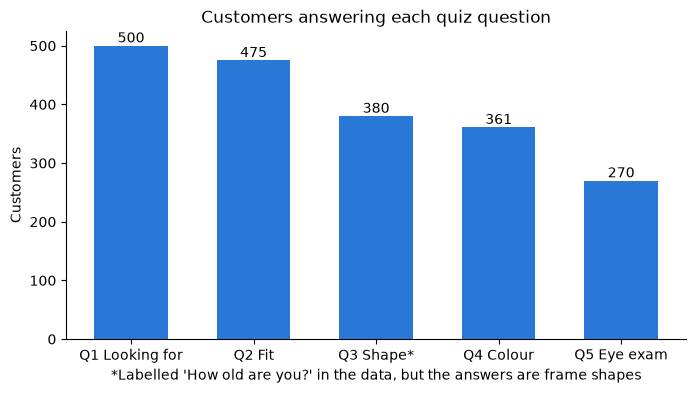

In [21]:
# Number of customers who answered each question (sorted by question number)
customers_per_question = survey.groupby("question")["user_id"].nunique()
question_names = ["Q1 Looking for", "Q2 Fit", "Q3 Shape*", "Q4 Colour", "Q5 Eye exam"]

bars = plt.bar(question_names, customers_per_question.values, color=blue, width=0.6)
plt.bar_label(bars)
plt.title("Customers answering each quiz question")
plt.ylabel("Customers")
plt.xlabel("*Labelled 'How old are you?' in the data, but the answers are frame shapes")
plt.show()

**Interpretation:** The number of customers falls at every question, from 500 to 270. The two biggest drops are at question 3 (475 to 380, a loss of 95) and question 5 (361 to 270, a loss of 91). Question 5, about the last eye exam, loses about a quarter of the customers who reach it.

### Step 3: The funnel from quiz to purchase

We count how many customers reach each stage and show each count as a percentage of the quiz.

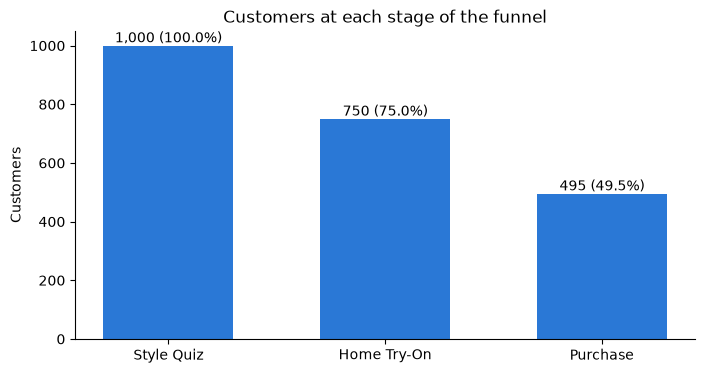

In [22]:
# Customers at each stage
stages = ["Style Quiz", "Home Try-On", "Purchase"]
counts = [len(funnel), funnel["got_home_try_on"].sum(), funnel["purchased"].sum()]

# Label each bar with the count and the percentage of quiz customers
labels = [f"{count:,} ({count / counts[0]:.1%})" for count in counts]

bars = plt.bar(stages, counts, color=blue, width=0.6)
plt.bar_label(bars, labels=labels)
plt.title("Customers at each stage of the funnel")
plt.ylabel("Customers")
plt.show()

**Interpretation:** Of 1,000 quiz customers, 750 (75.0%) received a home try-on box and 495 (49.5%) purchased. Among customers who received a box, 66.0% purchased (495 of 750). Each stage loses customers: 250 customers (25.0%) between the quiz and the try-on, and 255 customers (34.0%) between the try-on and the purchase.

### Step 4: Purchase rate for 3 pairs versus 5 pairs

Only customers who received a home try-on box can be in this comparison, so we select them first.

                 customers  purchases
number_of_pairs                      
3 pairs                379        201
5 pairs                371        294


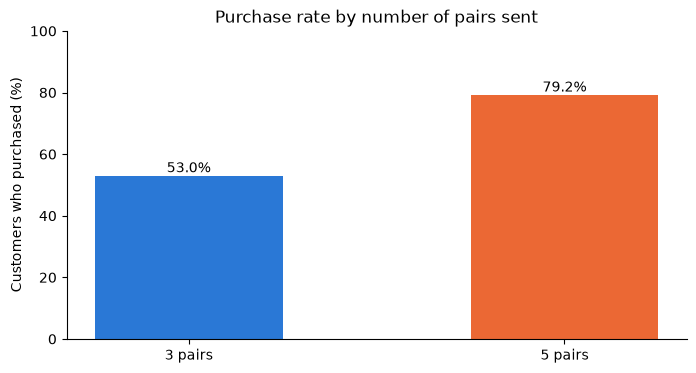

In [23]:
# Customers who received a home try-on box
tried = funnel[funnel["got_home_try_on"]]

# Customers and purchases in each group
print(tried.groupby("number_of_pairs")["purchased"].agg(customers="count", purchases="sum"))

# Purchase rate (%) in each group
purchase_rate = tried.groupby("number_of_pairs")["purchased"].mean() * 100

bars = plt.bar(purchase_rate.index, purchase_rate.values, color=[blue, orange], width=0.5)
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Purchase rate by number of pairs sent")
plt.ylabel("Customers who purchased (%)")
plt.ylim(0, 100)
plt.show()

**Interpretation:** 53.0% of customers sent 3 pairs purchased (201 of 379), compared with 79.2% of customers sent 5 pairs (294 of 371). That is a gap of 26.2 percentage points. This is a description of the data. We have not yet tested whether the gap could be due to chance.

### Step 5: Do the quiz answers relate to home try-on and purchase?

For each quiz question, we calculate the percentage of customers who received a box and the percentage who purchased. Both percentages are out of all quiz customers in that answer group.

In [24]:
# For each quiz question, the funnel results for each answer
for column in ["style", "fit", "shape", "color"]:
    summary = funnel.groupby(column).agg(
        customers=("user_id", "count"),
        home_try_on_pct=("got_home_try_on", "mean"),
        purchased_pct=("purchased", "mean"))
    summary["home_try_on_pct"] = (summary["home_try_on_pct"] * 100).round(1)
    summary["purchased_pct"] = (summary["purchased_pct"] * 100).round(1)
    print(summary)
    print()

                              customers  home_try_on_pct  purchased_pct
style                                                                  
I'm not sure. Let's skip it.         99             69.7            0.0
Men's Styles                        432             74.1           56.2
Women's Styles                      469             77.0           53.7

                              customers  home_try_on_pct  purchased_pct
fit                                                                    
I'm not sure. Let's skip it.         89             71.9           50.6
Medium                              305             76.7           49.8
Narrow                              408             74.0           47.3
Wide                                198             75.8           53.0

               customers  home_try_on_pct  purchased_pct
shape                                                   
No Preference         97             73.2           54.6
Rectangular          397           

The style question stands out: customers who answered "I'm not sure" received a box slightly less often (69.7%, compared with 74.1% and 77.0%) and none of them purchased. We look at this more closely using only customers who received a box.

style
Not sure           69
Men's Styles      320
Women's Styles    361
Name: purchased, dtype: int64


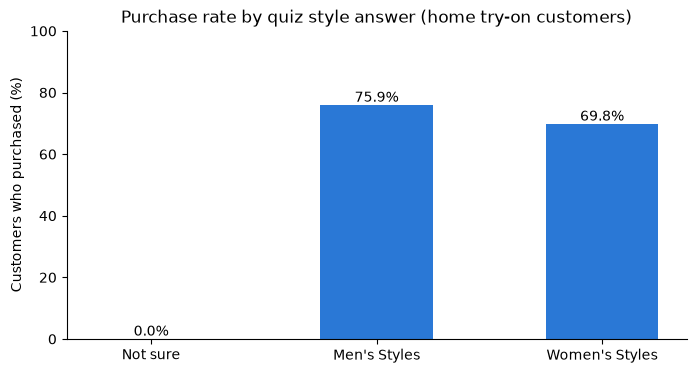

In [25]:
# Purchase rate among customers who received a box, by their style answer
style_rate = tried.groupby("style")["purchased"].mean() * 100
style_rate = style_rate.rename({"I'm not sure. Let's skip it.": "Not sure"})
style_customers = tried.groupby("style")["purchased"].count()
print(style_customers.rename({"I'm not sure. Let's skip it.": "Not sure"}))

bars = plt.bar(style_rate.index, style_rate.values, color=blue, width=0.5)
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Purchase rate by quiz style answer (home try-on customers)")
plt.ylabel("Customers who purchased (%)")
plt.ylim(0, 100)
plt.show()

**Interpretation:**

- **Style "I'm not sure":** 69 customers who skipped the style question received a try-on box and none purchased (0.0%). Customers who chose Men's or Women's styles purchased at 75.9% and 69.8%. We cannot tell why from this data. It may be worth checking how these customers are matched to frames.
- **Other quiz answers:** The purchase rate among home try-on customers stays between about 61% and 75% across fit, shape and colour answers. The lowest is the Neutral colour (60.8%) and the highest is the No Preference shape (74.6%). Several groups are small, so these differences should not be over-interpreted.

### Step 6: Are the 3-pair and 5-pair groups similar?

If the two groups contain a similar mix of customers, a difference in purchase rate is easier to trust. We compare the quiz answers in each group (percentages add up to 100 across each row).

In [26]:
# Mix of quiz answers in each group (%)
for column in ["style", "fit", "shape", "color"]:
    mix = pd.crosstab(tried["number_of_pairs"], tried[column], normalize="index") * 100
    print(mix.round(1))
    print()

style            I'm not sure. Let's skip it.  Men's Styles  Women's Styles
number_of_pairs                                                            
3 pairs                                   9.8          43.5            46.7
5 pairs                                   8.6          41.8            49.6

fit              I'm not sure. Let's skip it.  Medium  Narrow  Wide
number_of_pairs                                                    
3 pairs                                   8.4    33.0    40.9  17.7
5 pairs                                   8.6    29.4    39.6  22.4

shape            No Preference  Rectangular  Round  Square
number_of_pairs                                           
3 pairs                    9.2         39.3   20.1    31.4
5 pairs                    9.7         37.5   17.3    35.6

color            Black  Crystal  Neutral  Tortoise  Two-Tone
number_of_pairs                                             
3 pairs           27.4     21.9     10.3      29.0      11.3
5 

**Interpretation:** The two groups have a similar mix of quiz answers. For every answer, the share of customers differs by less than 5 percentage points between the 3-pair and 5-pair groups (the largest gap is for a Wide fit: 17.7% versus 22.4%). This is consistent with the groups being comparable, but it does not prove that customers were assigned at random, because we do not know how they were assigned.

### Step 7: What do customers buy?

We look at the number of purchases for each model and at the price paid.

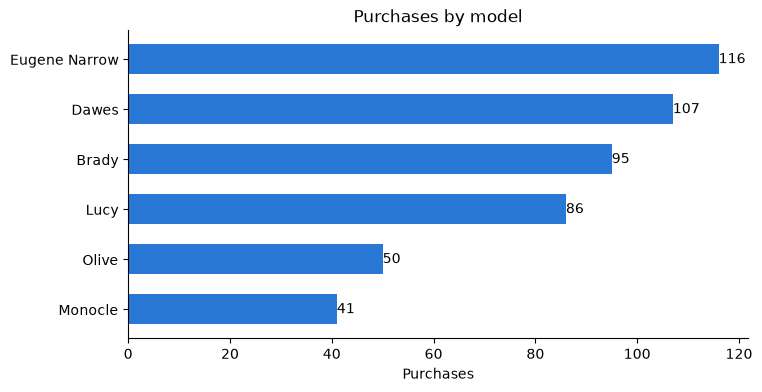

In [27]:
# Number of purchases for each model (smallest first so the largest appears at the top)
model_counts = purchase["model_name"].value_counts().sort_values()

bars = plt.barh(model_counts.index, model_counts.values, color=blue, height=0.6)
plt.bar_label(bars)
plt.title("Purchases by model")
plt.xlabel("Purchases")
plt.show()

In [28]:
# Summary of the prices paid
print(purchase["price"].describe().round(1))
print()

# Total purchase value for each model
print("Total purchase value by model:")
print(purchase.groupby("model_name")["price"].sum().sort_values(ascending=False))
print()
print("Total purchase value, all models:", purchase["price"].sum())

count    495.0
mean     112.7
std       32.2
min       50.0
25%       95.0
50%       95.0
75%      150.0
max      150.0
Name: price, dtype: float64

Total purchase value by model:
model_name
Dawes            16050
Lucy             12900
Eugene Narrow    11020
Brady             9025
Olive             4750
Monocle           2050
Name: price, dtype: int64

Total purchase value, all models: 55795


**Interpretation:** Eugene Narrow is the most purchased model (116), followed by Dawes (107) and Brady (95). Prices are 50, 95 or 150, with an average of 112.7 and a median of 95. Dawes has the highest total purchase value (16,050) even though it has fewer purchases than Eugene Narrow, because Dawes costs 150 and Eugene Narrow costs 95. Monocle is the cheapest model (50) and the least purchased (41).

### Step 8: Summary of the exploratory analysis

1. **Funnel:** 1,000 quiz customers, 750 home try-on (75.0%) and 495 purchases (49.5%). Of customers who received a box, 66.0% purchased.
2. **Quiz drop-off:** Survey customers fall from 500 at question 1 to 270 at question 5. The biggest drops are at question 3 and question 5.
3. **3 versus 5 pairs:** The purchase rate is 53.0% for 3 pairs and 79.2% for 5 pairs. This is a gap of 26.2 percentage points that still needs a statistical test.
4. **Style "I'm not sure":** 69 customers who skipped the style question received a box and none purchased.
5. **Group comparison:** The 3-pair and 5-pair groups have a similar mix of quiz answers.
6. **Products:** Eugene Narrow, Dawes and Brady are the most purchased models. Dawes brings in the highest total purchase value.

**Limitations**

- The survey customers cannot be matched to the funnel customers, so the quiz drop-off numbers describe a different group.
- The data does not show how customers were assigned to 3 or 5 pairs.
- These are descriptions only. We have not tested whether any difference could be due to chance.

---
## Business Interpretation

**Business question:** What do the results from SQL, Python and R tell Warby Parker about its customer journey, and how far can we trust them?

**Method:** We bring together the results from the SQL funnel queries (`analysis.sql`), the exploratory analysis above and the A/B test (`analysis.R`). This section explains what each finding means. Recommendations come later.

### 1. Where do customers leave the Style Quiz?

| Question | Customers answering | Share of the previous question |
|---|---|---|
| Q1 Looking for | 500 | |
| Q2 Fit | 475 | 95.0% |
| Q3 Shape | 380 | 80.0% |
| Q4 Colour | 361 | 95.0% |
| Q5 Last eye exam | 270 | 74.8% |

**What it means:** Only 54.0% of customers who start the quiz reach the last question. Most of the loss happens at two points: question 3 (95 customers lost, 20.0% of those who reached it) and question 5 (91 customers lost, 25.2%). The other questions each lose about 5%.

**Possible reasons (not proven by this data):** Question 5 asks about the last eye exam, which may feel less related to choosing frames. Question 3 is the one whose label in the data does not match its answers. We cannot tell from the data why customers stop.

**How far to trust it:** The survey customers cannot be matched to the funnel customers (none of the IDs match), so this describes a separate group of 500 customers.

### 2. How many customers move from quiz to home try-on to purchase?

| Stage | Customers | Share of quiz | Share of previous stage |
|---|---|---|---|
| Style Quiz | 1,000 | 100.0% | |
| Home Try-On | 750 | 75.0% | 75.0% |
| Purchase | 495 | 49.5% | 66.0% |

**What it means:** About half of the customers who take the quiz end up buying glasses. The two steps lose a similar number of customers: 250 between the quiz and the try-on, and 255 between the try-on and the purchase. Since the second step starts from fewer customers, it loses a larger share (34.0% of customers who received a box did not buy).

**How far to trust it:** High. The tables match step by step (every try-on customer is in the quiz, and every purchaser is in the try-on group), and the joins did not duplicate any customers.

### 3. Does sending 5 pairs instead of 3 change the purchase rate?

| | 3 pairs | 5 pairs |
|---|---|---|
| Customers | 379 | 371 |
| Purchases | 201 | 294 |
| Purchase rate | 53.0% | 79.2% |

**What it means:** Customers sent 5 pairs purchased much more often: 26.2 percentage points higher, with a 95% confidence interval of 19.4 to 33.0 points. The p-value is 6.4e-14, so a gap this large is very unlikely to be due to chance. Put simply, about 26 more customers purchase for every 100 who receive a box with 5 pairs instead of 3.

**Is the difference important for the business?** Yes, it is large, not just statistically significant. Even the low end of the confidence interval (19.4 points) is a big improvement.

**How far to trust it:** The size of the difference is clear, but the reason for it is less certain:
- The data does not say how customers were given 3 or 5 pairs. If it was not random, we cannot say that 5 pairs *caused* the higher purchase rate.
- The two groups have a similar mix of quiz answers (every answer within 5 percentage points), which is reassuring but is not proof of random assignment.
- The test does not include the cost of sending 2 extra pairs.

### 4. Customers who answered "I'm not sure" to the style question

Of the 99 quiz customers who skipped the style question, 69 received a home try-on box and **none purchased** (0 of 69). Customers who chose Men's or Women's styles purchased at 75.9% and 69.8%.

**What it means:** This is a clear pattern, but the data does not explain it. It does not explain the 3 versus 5 pairs result: the A/B test gives the same conclusion without these customers (58.8% versus 86.7%, a gap of 28.0 points), and both groups had a similar share of them.

**How far to trust it:** The pattern itself is certain (it is a count). The cause is unknown. It may reflect how the data was generated or how these customers are matched to frames, so it should be checked with the business before drawing conclusions.

### 5. What do customers buy?

Eugene Narrow (116 purchases), Dawes (107) and Brady (95) are the most purchased models. Dawes has the highest total purchase value (16,050) because it is priced at 150, compared with 95 for Eugene Narrow. Prices are 50, 95 or 150, with an average of 112.7.

**How far to trust it:** This is a description of one set of purchases. It does not show why customers prefer certain models.

### Summary: what we can and cannot say

| Finding | Strength of evidence | Main caution |
|---|---|---|
| About half of quiz customers buy (49.5%) | Strong | None significant |
| Quiz drop-off is biggest at questions 3 and 5 | Moderate | Survey customers cannot be linked to the funnel; reasons are unknown |
| 5 pairs gives a much higher purchase rate (+26.2 points) | Strong that the difference is real | Assignment method unknown, so causation is not proven; cost not included |
| "I'm not sure" style customers never purchased | Certain as a count | Cause unknown |
| Eugene Narrow, Dawes and Brady are the top models | Moderate | Descriptive only |

**Next:** data visualisation, then business recommendations.

---
## Dashboard

**Business question:** Can the main results be shown on one page that a non-technical reader understands in under a minute?

**Method:** Reuse the numbers already calculated above and place three headline numbers and three charts on one page. Each chart title states its finding. The page is saved as `dashboard.png`.

### Step 1: Build the one-page dashboard

The top row has three headline numbers. The bottom row has the funnel, the quiz drop-off and the 3 versus 5 pairs comparison. The numbers come from variables created in the exploratory analysis (`counts`, `customers_per_question` and `purchase_rate`), so run the notebook from the top.

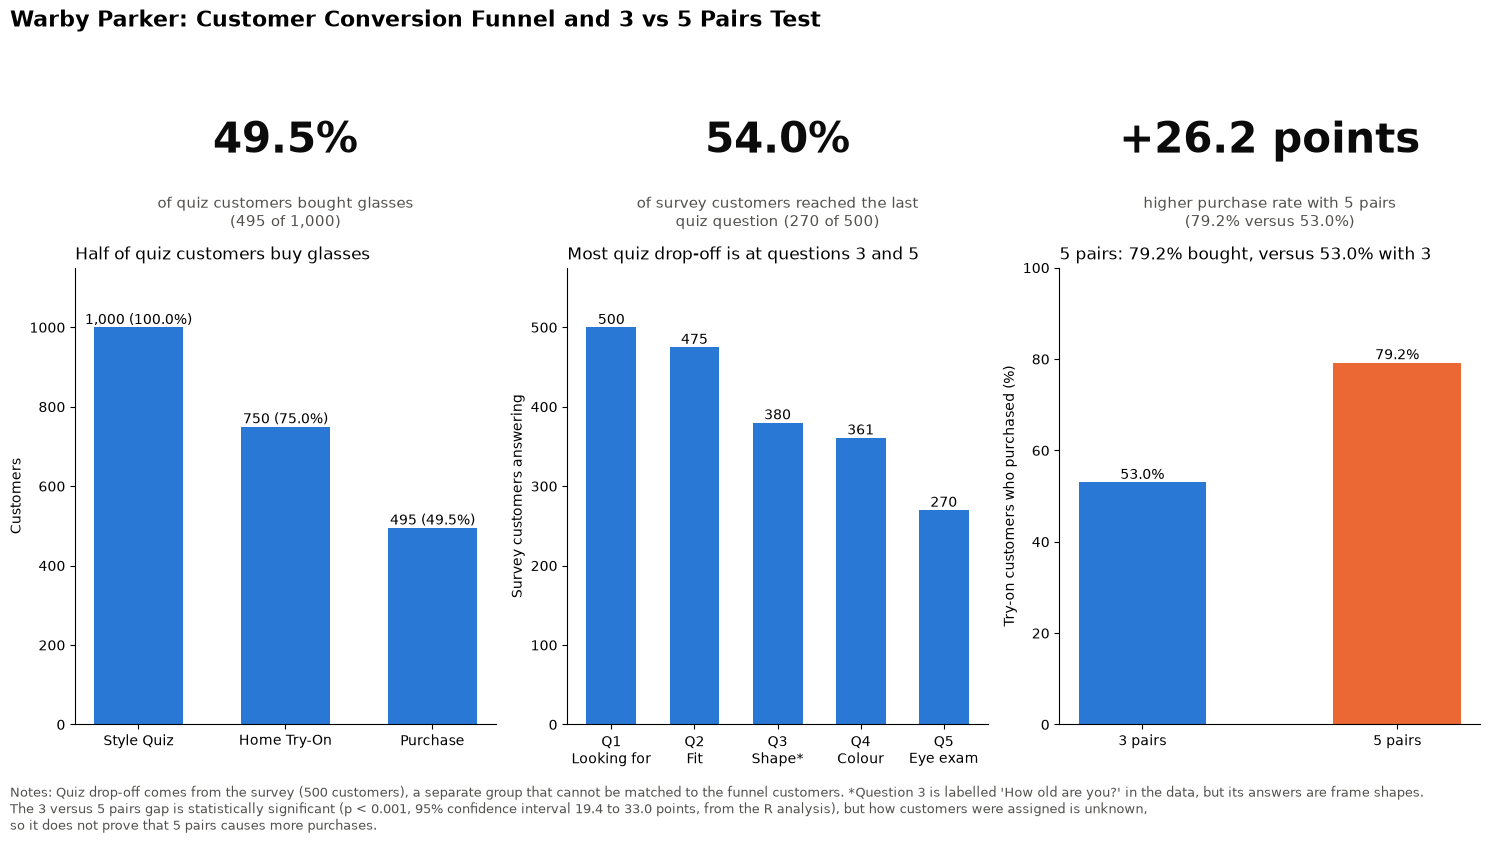

In [29]:
# Numbers for the headline cards, calculated from the earlier results
conversion = counts[2] / counts[0] * 100
finish_rate = customers_per_question.iloc[-1] / customers_per_question.iloc[0] * 100
gap = purchase_rate["5 pairs"] - purchase_rate["3 pairs"]

# Text colours and short question names for the chart
dark_text = "#0b0b0b"
grey_text = "#52514e"
dashboard_names = ["Q1\nLooking for", "Q2\nFit", "Q3\nShape*", "Q4\nColour", "Q5\nEye exam"]

# A page with 2 rows and 3 columns: the top row is thinner and holds the headline numbers
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), gridspec_kw={"height_ratios": [1, 3.2]})
fig.patch.set_facecolor("white")
fig.suptitle("Warby Parker: Customer Conversion Funnel and 3 vs 5 Pairs Test",
             fontsize=16, fontweight="bold", x=0.01, ha="left")

# Top row: three headline numbers
cards = [
    (f"{conversion:.1f}%", f"of quiz customers bought glasses\n({counts[2]:,} of {counts[0]:,})"),
    (f"{finish_rate:.1f}%", f"of survey customers reached the last\nquiz question ({customers_per_question.iloc[-1]} of {customers_per_question.iloc[0]})"),
    (f"+{gap:.1f} points", f"higher purchase rate with 5 pairs\n({purchase_rate['5 pairs']:.1f}% versus {purchase_rate['3 pairs']:.1f}%)")]

for ax, (big_number, description) in zip(axes[0], cards):
    ax.axis("off")
    ax.text(0.5, 0.62, big_number, ha="center", va="center", fontsize=30, fontweight="bold", color=dark_text)
    ax.text(0.5, 0.12, description, ha="center", va="center", fontsize=11, color=grey_text)

# Bottom left: the funnel
ax = axes[1][0]
bars = ax.bar(stages, counts, color=blue, width=0.6)
ax.bar_label(bars, labels=labels)
ax.set_title("Half of quiz customers buy glasses", loc="left", fontsize=12)
ax.set_ylabel("Customers")
ax.set_ylim(0, 1150)

# Bottom middle: the quiz drop-off
ax = axes[1][1]
bars = ax.bar(dashboard_names, customers_per_question.values, color=blue, width=0.6)
ax.bar_label(bars)
ax.set_title("Most quiz drop-off is at questions 3 and 5", loc="left", fontsize=12)
ax.set_ylabel("Survey customers answering")
ax.set_ylim(0, 575)

# Bottom right: purchase rate for 3 and 5 pairs
ax = axes[1][2]
bars = ax.bar(purchase_rate.index, purchase_rate.values, color=[blue, orange], width=0.5)
ax.bar_label(bars, fmt="%.1f%%")
ax.set_title(f"5 pairs: {purchase_rate['5 pairs']:.1f}% bought, versus {purchase_rate['3 pairs']:.1f}% with 3", loc="left", fontsize=12)
ax.set_ylabel("Try-on customers who purchased (%)")
ax.set_ylim(0, 100)

# Footnote with the main limits
note = ("Notes: Quiz drop-off comes from the survey (500 customers), a separate group that cannot be matched to the funnel customers. "
        "*Question 3 is labelled 'How old are you?' in the data, but its answers are frame shapes.\n"
        "The 3 versus 5 pairs gap is statistically significant (p < 0.001, 95% confidence interval 19.4 to 33.0 points, from the R analysis), "
        "but how customers were assigned is unknown,\nso it does not prove that 5 pairs causes more purchases.")
fig.text(0.01, 0.01, note, fontsize=9, color=grey_text, ha="left", va="bottom")

fig.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.savefig("dashboard.png", dpi=150, facecolor="white")
plt.show()

**Interpretation:** The page shows the whole story in one view. About half of the quiz customers buy glasses, quiz customers drop out mainly at questions 3 and 5, and customers sent 5 pairs buy far more often than customers sent 3. The footnote keeps the main limits visible, so the page does not over-claim.

### Step 2: Export tidy data files for Power BI

The original CSV files have no column names. Here we save four small files with clear names in a new `powerbi/` folder, so they can be loaded straight into Power BI. The numbers all come from this notebook, and the original files in `data/` are not changed.

- `funnel.csv`: one row per quiz customer, with 1/0 columns for the try-on and purchase (1/0 columns can be summed into counts).
- `funnel_stages.csv`: the three funnel stages and their customer counts.
- `quiz_dropoff.csv`: the number of survey customers answering each question.
- `purchases.csv`: one row per purchase.

In [30]:
# Import the os library to create a folder
import os
os.makedirs("powerbi", exist_ok=True)

# 1. Funnel table: one row per quiz customer. True/False becomes 1/0 so Power BI can add them up
funnel_export = funnel.copy()
funnel_export["got_home_try_on"] = funnel_export["got_home_try_on"].astype(int)
funnel_export["purchased"] = funnel_export["purchased"].astype(int)
funnel_export["number_of_pairs"] = funnel_export["number_of_pairs"].fillna("No box")
funnel_export.to_csv("powerbi/funnel.csv", index=False)

# 2. Funnel stages
funnel_stages = pd.DataFrame({"stage_order": [1, 2, 3], "stage": stages, "customers": counts})
funnel_stages["pct_of_quiz"] = (funnel_stages["customers"] / counts[0] * 100).round(1)
funnel_stages.to_csv("powerbi/funnel_stages.csv", index=False)

# 3. Quiz drop-off from the survey
quiz_dropoff = pd.DataFrame({"question_number": [1, 2, 3, 4, 5],
                             "question": question_names,
                             "customers": customers_per_question.values})
quiz_dropoff.to_csv("powerbi/quiz_dropoff.csv", index=False)

# 4. Purchases
purchase.to_csv("powerbi/purchases.csv", index=False)

# Check what was saved by reading each file back
for file_name in ["funnel", "funnel_stages", "quiz_dropoff", "purchases"]:
    saved = pd.read_csv(f"powerbi/{file_name}.csv")
    print(file_name, "-", saved.shape[0], "rows,", saved.shape[1], "columns")
print()
print(pd.read_csv("powerbi/funnel_stages.csv"))
print()
print(pd.read_csv("powerbi/quiz_dropoff.csv"))

funnel - 1000 rows, 8 columns
funnel_stages - 3 rows, 4 columns
quiz_dropoff - 5 rows, 3 columns
purchases - 495 rows, 6 columns

   stage_order        stage  customers  pct_of_quiz
0            1   Style Quiz       1000        100.0
1            2  Home Try-On        750         75.0
2            3     Purchase        495         49.5

   question_number        question  customers
0                1  Q1 Looking for        500
1                2          Q2 Fit        475
2                3       Q3 Shape*        380
3                4       Q4 Colour        361
4                5     Q5 Eye exam        270
